--- Fit Results for 50% Glycerol $T_1$ Recovery ---
Calculated T1: 288.93 ± 1.67 ms
Fitted plateau (a): 6.02 ± 0.04 V
Fitted amplitude (k): 12.33 ± 0.03 V



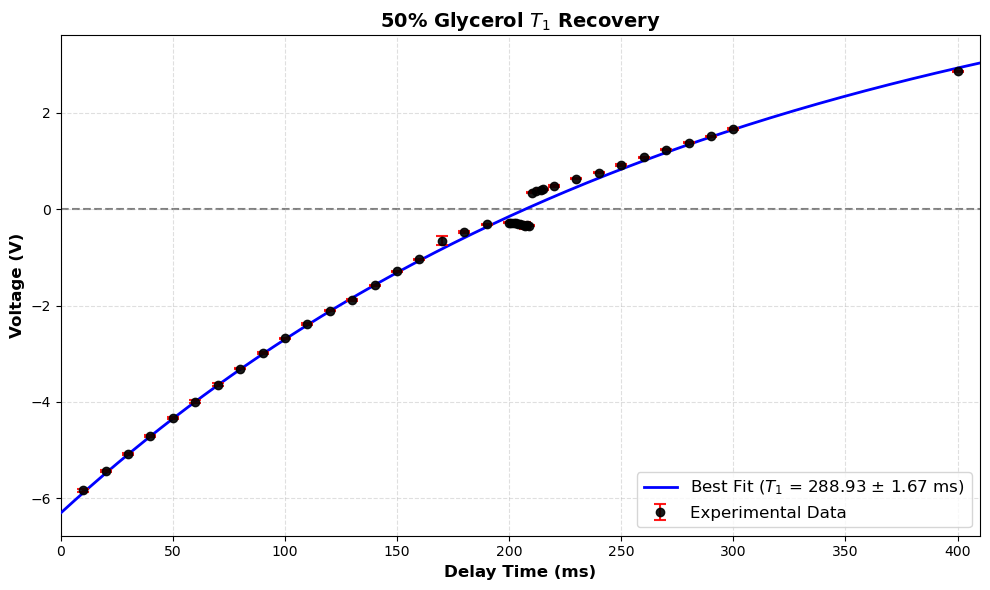

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path

# Process 90% Glycerol using your exact file path
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\50% glycerol\T1.csv",  '50% Glycerol $T_1$ Recovery')


Estimated Period: 0.002335 s
Number of mapped peaks: 98
Diffusion term K = 1.215273e-09 s^-1

--- Diffusion-Corrected Fit Results ---
A = 3.074245 V
T2_actual = 0.115429 s
T2_observed (what raw decay shows) = 0.115429 s
Baseline C = 0.589427 V


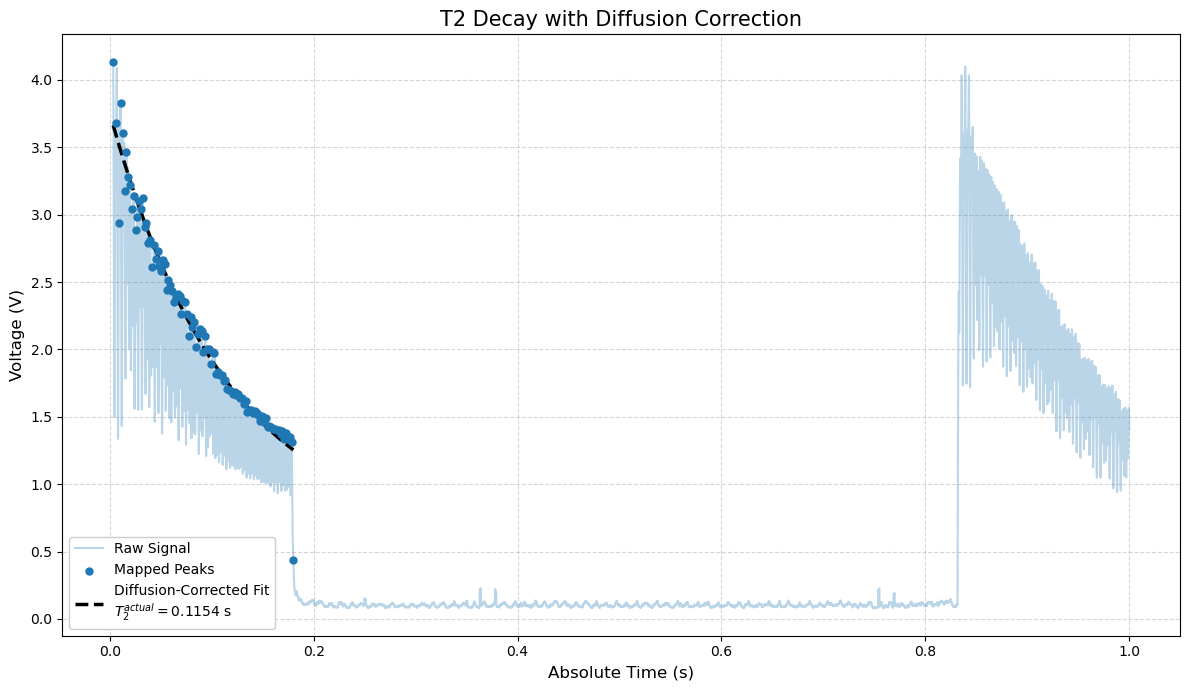

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# -----------------------------
# 1. Load ONLY first two columns (ignore all others)
# -----------------------------
file = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\50% glycerol\T2.csv"

data = pd.read_csv(
    file,
    encoding='windows-1252',
    skiprows=1,
    usecols=[0, 1]  # <-- This discards all extra columns automatically
)

data.columns = ['time', 'voltage']

# Convert to numeric safely
data['time'] = pd.to_numeric(data['time'], errors='coerce')
data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

# -----------------------------
# 2. Find global maximum (start of decay)
# -----------------------------
vmaxid = data['voltage'].idxmax()
t_start_analysis = data.loc[vmaxid, 'time']

# -----------------------------
# 3. Estimate period from rough peaks
# -----------------------------
post_peak_data = data.loc[vmaxid:].copy()
min_prominence = post_peak_data['voltage'].max() * 0.05

peaks_rough, _ = find_peaks(
    post_peak_data['voltage'],
    distance=20,
    prominence=min_prominence
)

t_peaks = post_peak_data.iloc[peaks_rough]['time'].values

# Safety check in case few peaks detected
if len(t_peaks) > 5:
    period_guess = np.mean(np.diff(t_peaks[:5]))
else:
    period_guess = np.mean(np.diff(t_peaks))

print(f"Estimated Period: {period_guess:.6f} s")

# -----------------------------
# 4. Sequential windowed peak mapping
# -----------------------------
refined_times = []
refined_voltages = []

window_half_width = period_guess * 0.25
current_time_guess = t_start_analysis

max_iterations = 98  # desired number of echoes

for i in range(max_iterations):
    t_start = current_time_guess - window_half_width
    t_end = current_time_guess + window_half_width
    
    window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
    
    if window.empty:
        break  # stop instead of creating mismatched lengths
    
    max_idx = window['voltage'].idxmax()
    actual_max_t = window.loc[max_idx, 'time']
    actual_max_v = window.loc[max_idx, 'voltage']
    
    refined_times.append(actual_max_t)
    refined_voltages.append(actual_max_v)
    
    current_time_guess = actual_max_t + period_guess

peak_results = pd.DataFrame({
    'Time': refined_times,
    'Voltage': refined_voltages
})

print(f"Number of mapped peaks: {len(peak_results)}")

# -----------------------------
# 5. Prepare data for fitting (fix length mismatch)
# -----------------------------
t_zeroed = (peak_results['Time'] - peak_results['Time'].iloc[0]).to_numpy()
v_data = peak_results['Voltage'].to_numpy()

# -----------------------------
# 6. Diffusion parameters (SET THESE TO YOUR EXPERIMENT)
# -----------------------------
gamma = 2 * np.pi * 42.58e6   # rad s^-1 T^-1 (proton)
G = 0.1                       # T/m  <-- CHANGE
D = 1e-9                      # m^2/s <-- CHANGE (depends on glycerol %)
tau = period_guess / 2        # echo spacing approximation (can adjust)

K = gamma * (G**2) * D * (tau**2) / 3
print(f"Diffusion term K = {K:.6e} s^-1")

# -----------------------------
# 7. Diffusion-corrected decay model
#  V(t) = A * exp[-t(1/T2_actual + K)] + C
# -----------------------------
def decay_model(t, A, T2_actual, C):
    return A * np.exp(-t * (1.0 / T2_actual + K)) + C

# Initial guesses
A_guess = v_data.max() - v_data.min()
T2_guess = t_zeroed[-1] / 3
C_guess = v_data.min()
initial_guess = [A_guess, T2_guess, C_guess]

# Curve fit (directly returns T2_actual)
popt, pcov = curve_fit(decay_model, t_zeroed, v_data, p0=initial_guess, maxfev=10000)
A_fit, T2_actual_fit, C_fit = popt

# Also compute observed T2 for reference
T2_observed = 1.0 / (1.0 / T2_actual_fit + K)

print("\n--- Diffusion-Corrected Fit Results ---")
print(f"A = {A_fit:.6f} V")
print(f"T2_actual = {T2_actual_fit:.6f} s")
print(f"T2_observed (what raw decay shows) = {T2_observed:.6f} s")
print(f"Baseline C = {C_fit:.6f} V")

# -----------------------------
# 8. Smooth fit curve
# -----------------------------
t_smooth = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
v_smooth = decay_model(t_smooth, A_fit, T2_actual_fit, C_fit)
t_smooth_absolute = t_smooth + peak_results['Time'].iloc[0]

# -----------------------------
# 9. Plot
# -----------------------------
plt.figure(figsize=(12, 7))

plt.plot(
    data.loc[vmaxid:, 'time'],
    data.loc[vmaxid:, 'voltage'],
    alpha=0.3,
    label='Raw Signal'
)

plt.scatter(
    peak_results['Time'],
    peak_results['Voltage'],
    s=25,
    label='Mapped Peaks',
    zorder=5
)

plt.plot(
    t_smooth_absolute,
    v_smooth,
    'k--',
    linewidth=2.5,
    label=f'Diffusion-Corrected Fit\n$T_2^{{actual}} = {T2_actual_fit:.4f}$ s'
)

plt.title('T2 Decay with Diffusion Correction', fontsize=15)
plt.xlabel('Absolute Time (s)', fontsize=12)
plt.ylabel('Voltage (V)', fontsize=12)
plt.legend(framealpha=1.0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

--- NMR Analysis @ 12.53 MHz ---
Diffusion Term K: 6.50e-02 s^-1
T2 Actual: 0.116301 s
T2 Observed: 0.115428 s
Difference: 0.8729 ms


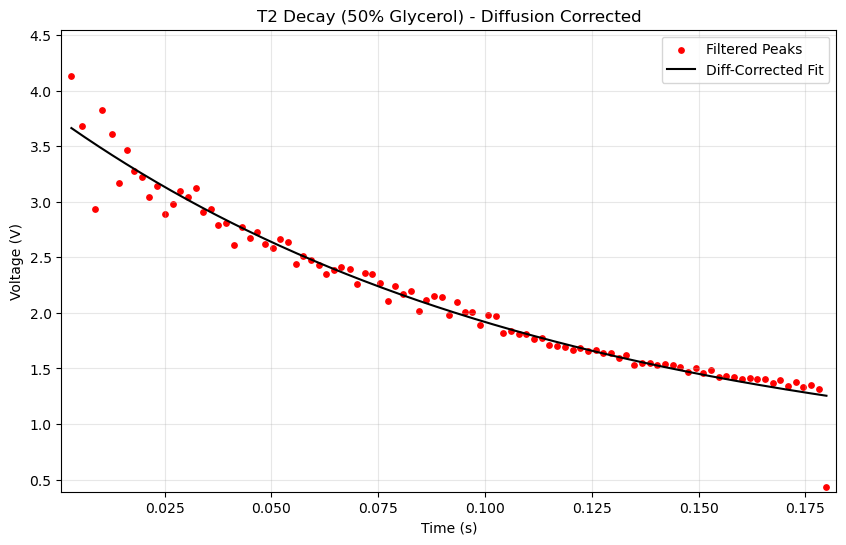

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# -----------------------------
# 1. Load Data
# -----------------------------
file = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\50% glycerol\T2.csv"
data = pd.read_csv(file, encoding='windows-1252', skiprows=1, usecols=[0, 1])
data.columns = ['time', 'voltage']
data['time'] = pd.to_numeric(data['time'], errors='coerce')
data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
data = data.dropna().reset_index(drop=True)

# -----------------------------
# 2. Find start of decay
# -----------------------------
vmaxid = data['voltage'].idxmax()
t_start_analysis = data.loc[vmaxid, 'time']

# -----------------------------
# 3. Estimate period
# -----------------------------
post_peak_data = data.loc[vmaxid:].copy()
peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=20, prominence=post_peak_data['voltage'].max() * 0.05)
t_peaks = post_peak_data.iloc[peaks_rough]['time'].values
period_guess = np.mean(np.diff(t_peaks[:5])) if len(t_peaks) > 5 else np.mean(np.diff(t_peaks))

# -----------------------------
# 4. Refined Peak Mapping (Fixing the "Extra Peak")
# -----------------------------
refined_times, refined_voltages = [], []
window_half_width = period_guess * 0.25
current_time_guess = t_start_analysis
max_iterations = 98 

for i in range(max_iterations):
    t_start, t_end = current_time_guess - window_half_width, current_time_guess + window_half_width
    
    # Boundary Check: Prevent picking up noise/truncation at the very end of the file
    if t_end > data['time'].max():
        break
        
    window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
    if window.empty: break
    
    max_idx = window['voltage'].idxmax()
    refined_times.append(window.loc[max_idx, 'time'])
    refined_voltages.append(window.loc[max_idx, 'voltage'])
    current_time_guess = refined_times[-1] + period_guess

peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})

# -----------------------------
# 5. Parameters & Diffusion Math
# -----------------------------
# Resonant freq: 12.530807 MHz -> Gamma is fixed for Protons
gamma = 2 * np.pi * 42.58e6   
G = 0.1                       # Gradient (T/m) - Adjust based on your magnet
D = 0.2e-9                    # Diffusion for 50% Glycerol (m^2/s)
tau = period_guess / 2        

K = (gamma**2 * G**2 * D * tau**2) / 3

# -----------------------------
# 6. Curve Fitting
# -----------------------------
t_zeroed = (peak_results['Time'] - peak_results['Time'].iloc[0]).to_numpy()
v_data = peak_results['Voltage'].to_numpy()

def decay_model(t, A, T2_actual, C):
    return A * np.exp(-t * (1.0 / T2_actual + K)) + C

popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[v_data.max(), t_zeroed[-1]/3, v_data.min()])
A_fit, T2_actual_fit, C_fit = popt
T2_observed = 1.0 / (1.0 / T2_actual_fit + K)

# -----------------------------
# 7. Print Diagnostics
# -----------------------------
print(f"--- NMR Analysis @ 12.53 MHz ---")
print(f"Diffusion Term K: {K:.2e} s^-1")
print(f"T2 Actual: {T2_actual_fit:.6f} s")
print(f"T2 Observed: {T2_observed:.6f} s")
print(f"Difference: {abs(T2_actual_fit - T2_observed)*1000:.4f} ms")

# -----------------------------
# 8. Plotting (Shortened Axis)
# -----------------------------
plt.figure(figsize=(10, 6))
plt.scatter(peak_results['Time'], peak_results['Voltage'], color='red', s=15, label='Filtered Peaks')

t_smooth = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
v_smooth = decay_model(t_smooth, A_fit, T2_actual_fit, C_fit)
plt.plot(t_smooth + peak_results['Time'].iloc[0], v_smooth, 'k-', label='Diff-Corrected Fit')

# Narrow the view to just the peaks we found
plt.xlim(peak_results['Time'].min() - period_guess, peak_results['Time'].max() + period_guess)
plt.ylim(peak_results['Voltage'].min() * 0.9, peak_results['Voltage'].max() * 1.1)

plt.title('T2 Decay (50% Glycerol) - Diffusion Corrected')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

--- Physics Parameters ---
Input Viscosity : 6.0 cP
Calculated D    : 1.818935e-10 m^2/s
Echo Spacing    : 0.002335 s
Diff Penalty (K): 7.866983e-03 s^-1

--- Fit Results ---
T2 (Actual)     = 0.101788 s
T2 (Raw/Obs)    = 0.101707 s
R-squared       = 0.9748


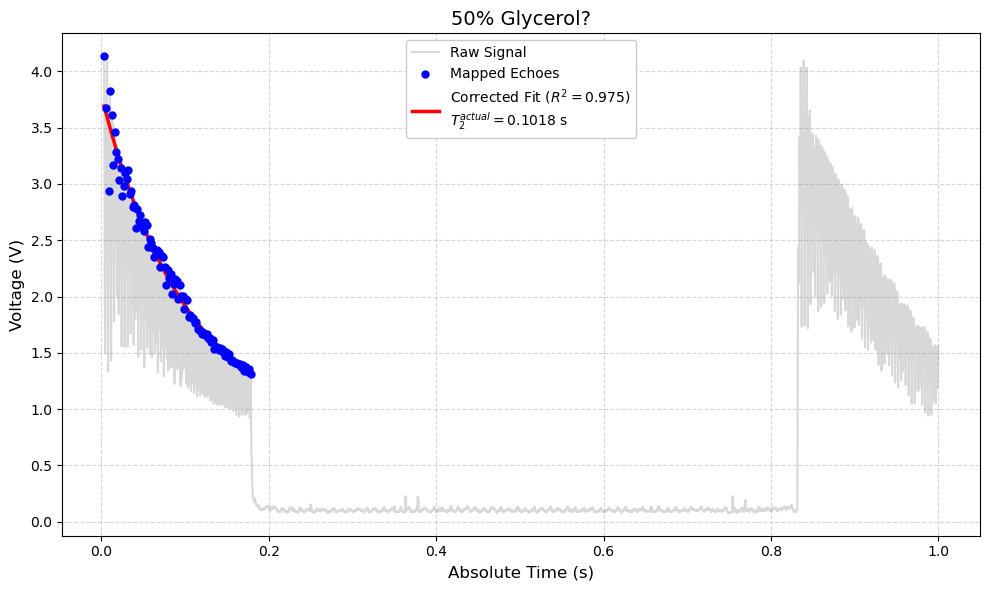

(np.float64(0.10178844498247804), np.float64(0.10170700127853198))

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_with_viscosity(file_path, plot_title, viscosity_cP, G=0.1, max_echoes=98, temp_K=298):
    """
    Analyzes T2 CPMG data using Viscosity to automatically calculate the Diffusion penalty.
    
    Parameters:
    - file_path: Path to the CSV.
    - plot_title: Title for the graph.
    - viscosity_cP: Viscosity of the sample in cP (centipoise or mPa*s).
    - G: Magnetic field gradient (T/m).
    - max_echoes: Number of peaks to map.
    - temp_K: Absolute temperature in Kelvin (default 298 K / 25 C).
    """
    # -----------------------------
    # 1. Calculate D from Viscosity (Stokes-Einstein)
    # -----------------------------
    k_B = 1.380649e-23  # Boltzmann constant (J/K)
    r = 2.0e-10         # Approx effective hydrodynamic radius (0.2 nm)
    
    # Convert viscosity from cP to SI units (Pa*s or kg/(m*s))
    eta_Pa_s = viscosity_cP * 1e-3
    
    # Calculate D
    D = (k_B * temp_K) / (6 * np.pi * eta_Pa_s * r)
    
    print("--- Physics Parameters ---")
    print(f"Input Viscosity : {viscosity_cP} cP")
    print(f"Calculated D    : {D:.6e} m^2/s")

    # -----------------------------
    # 2. Load & Clean Data
    # -----------------------------
    data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1, usecols=[0, 1])
    data.columns = ['time', 'voltage']

    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']

    # -----------------------------
    # 3. Estimate Echo Spacing
    # -----------------------------
    post_peak_data = data.loc[vmaxid:].copy()
    min_prominence = post_peak_data['voltage'].max() * 0.05

    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=20, prominence=min_prominence)
    t_peaks = post_peak_data.iloc[peaks_rough]['time'].values

    if len(t_peaks) > 5:
        period_guess = np.mean(np.diff(t_peaks[:5]))
    else:
        period_guess = np.mean(np.diff(t_peaks))

    print(f"Echo Spacing    : {period_guess:.6f} s")

    # -----------------------------
    # 4. Sequential windowed peak mapping
    # -----------------------------
    refined_times, refined_voltages = [], []
    window_half_width = period_guess * 0.25
    current_time_guess = t_start_analysis

    for i in range(max_echoes):
        t_start = current_time_guess - window_half_width
        t_end = current_time_guess + window_half_width
        
        window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
        if window.empty:
            break 
        
        max_idx = window['voltage'].idxmax()
        actual_max_t = window.loc[max_idx, 'time']
        actual_max_v = window.loc[max_idx, 'voltage']
        
        refined_times.append(actual_max_t)
        refined_voltages.append(actual_max_v)
        current_time_guess = actual_max_t + period_guess

    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})

    # -----------------------------
    # 5. Diffusion-Corrected Fit
    # -----------------------------
    t_zeroed = (peak_results['Time'] - peak_results['Time'].iloc[0]).to_numpy()
    v_data = peak_results['Voltage'].to_numpy()

    gamma = 2 * np.pi * 15.53e6   # rad s^-1 T^-1
    tau = period_guess / 2
    K = gamma**2 * (G**2) * D * (tau**2) / 3
    print(f"Diff Penalty (K): {K:.6e} s^-1")

    def decay_model(t, A, T2_actual, C):
        if T2_actual <= 0: return np.inf
        return A * np.exp(-t * (1.0 / T2_actual + K)) + C

    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed[-1] / 3
    C_guess = v_data.min()

    popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[A_guess, T2_guess, C_guess], maxfev=10000)
    A_fit, T2_actual_fit, C_fit = popt
    T2_observed = 1.0 / (1.0 / T2_actual_fit + K)

    residuals = v_data - decay_model(t_zeroed, *popt)
    r_sq = 1 - (np.sum(residuals**2) / np.sum((v_data - np.mean(v_data))**2))

    print("\n--- Fit Results ---")
    print(f"T2 (Actual)     = {T2_actual_fit:.6f} s")
    print(f"T2 (Raw/Obs)    = {T2_observed:.6f} s")
    print(f"R-squared       = {r_sq:.4f}")

    # -----------------------------
    # 6. Plotting
    # -----------------------------
    t_smooth = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_smooth = decay_model(t_smooth, A_fit, T2_actual_fit, C_fit)
    t_smooth_absolute = t_smooth + peak_results['Time'].iloc[0]

    plt.figure(figsize=(10, 6))
    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], alpha=0.3, label='Raw Signal', color='gray')
    plt.scatter(peak_results['Time'], peak_results['Voltage'], s=25, color='blue', label='Mapped Echoes', zorder=5)
    
    fit_label = f'Corrected Fit ($R^2={r_sq:.3f}$)\n$T_2^{{actual}} = {T2_actual_fit:.4f}$ s'
    plt.plot(t_smooth_absolute, v_smooth, 'r-', linewidth=2.5, label=fit_label)

    plt.title(plot_title, fontsize=14)
    plt.xlabel('Absolute Time (s)', fontsize=12)
    plt.ylabel('Voltage (V)', fontsize=12)
    plt.legend(framealpha=1.0)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    return T2_actual_fit, T2_observed
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T2.csv", "50% Glycerol", viscosity_cP=6.0, max_echoes=97)